# Entanglement Swapping on an IBM Quantum Computer

**Goal:** entangle two qubits (`q0` and `q3`) that have **never interacted**, by performing a
Bell-state measurement (BSM) on their partners (`q1` and `q2`).

```
  q0 ──┐                         q0 ═╗
       │ Bell pair A              ║  entangled after the BSM
  q1 ──┘ ┐                         ║  (even though q0 and q3
         │ Bell measurement        ║   never touched)
  q2 ──┐ ┘                         ║
       │ Bell pair B              ║
  q3 ──┘                         q3 ═╝
```

### Protocol
1. Prepare two independent Bell pairs: $|\Phi^+\rangle_{01}\otimes|\Phi^+\rangle_{23}$.
2. Bell-measure `q1, q2` (CNOT `q1→q2`, H on `q1`, measure both → bits $m_1, m_2$).
3. Identity: $|\Phi^+\rangle_{01}|\Phi^+\rangle_{23} = \tfrac12\sum_{B} |B\rangle_{03}|B\rangle_{12}$, so `q0, q3` collapse into the **same** Bell state that was found on `q1, q2`:

| $m_1 m_2$ | state of (q0, q3) | Pauli correction on q3 |
|---|---|---|
| 00 | $\Phi^+$ | $I$ |
| 01 ($m_2=1$) | $\Psi^+$ | $X$ |
| 10 ($m_1=1$) | $\Phi^-$ | $Z$ |
| 11 | $\Psi^-$ | $ZX$ |

### How we verify it
We measure `q0, q3` in the **XX**, **YY** and **ZZ** bases and estimate the fidelity with $|\Phi^+\rangle$:

$$F = \frac{1 + \langle XX\rangle - \langle YY\rangle + \langle ZZ\rangle}{4}$$

$F > 0.5$ is an **entanglement witness**: no separable state can exceed it.

### Experiments in this notebook
| Part | What | Corrections |
|---|---|---|
| 1 | Ideal local simulation (sanity check) | classical post-processing |
| 2 | **IBM hardware run** + control experiment (no BSM) | classical post-processing |
| 3 | *(optional)* Dynamic circuit with real-time feed-forward | `if_test` on hardware |

## 0. Setup

Put your IBM Quantum credentials in a `.env` file next to this notebook (see `.env.example`):

```
QISKIT_IBM_TOKEN=your_api_key
QISKIT_IBM_INSTANCE=your_instance_crn      # optional
IBM_BACKEND=ibm_xxx                         # optional, otherwise least-busy is used
```

In [1]:
import json
import os
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import qiskit
import qiskit_ibm_runtime
from dotenv import load_dotenv
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.primitives import StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler

print("qiskit            ", qiskit.__version__)
print("qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

qiskit             2.5.2
qiskit-ibm-runtime 0.50.0


In [2]:
load_dotenv()

SHOTS = 4000                                   # per circuit
BACKEND_NAME = os.getenv("IBM_BACKEND") or None  # None -> least busy backend
RUN_DYNAMIC = False                            # Part 3: set True to also run the feed-forward version

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

BASES = ["XX", "YY", "ZZ"]
BELL_LABELS = {"00": "Φ+", "01": "Ψ+", "10": "Φ-", "11": "Ψ-"}  # key = m1 m2

## 1. Build the circuits

Register layout (kept identical in every circuit so the analysis is shared):

- `bsm[0]` = $m_1$ (q1), `bsm[1]` = $m_2$ (q2) — the Bell-measurement result
- `out[0]` = q0, `out[1]` = q3 — the swapped pair

Qiskit bitstrings are little-endian, so the helper below converts them to `m1 m2` explicitly.

The **control** circuit skips the Bell measurement (q1, q2 are measured in the plain Z basis).
In that case q0 and q3 collapse to the product state $|m_1
angle|m_2
angle$: they keep a classical ZZ correlation
(per-outcome $F$ is 0.5 or 0, never above the separable limit), and the corrected fidelity is ≈ 0.25.

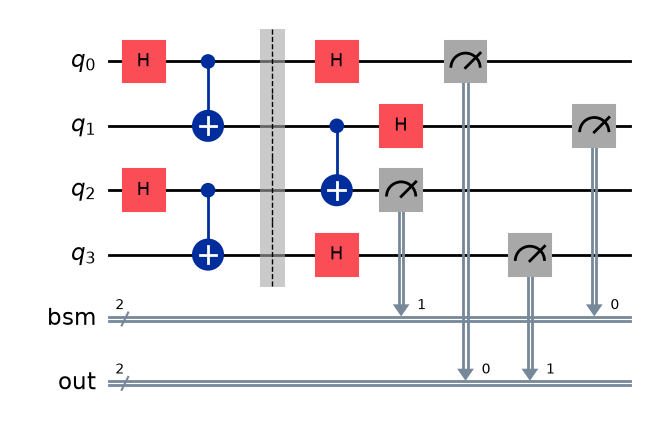

In [3]:
def add_basis_measurement(qc, basis, qubit):
    # Rotate so that a Z-measurement measures the requested Pauli.
    if basis == "X":
        qc.h(qubit)
    elif basis == "Y":
        qc.sdg(qubit)
        qc.h(qubit)


def build_swap_circuit(basis, bell_measurement=True, feed_forward=False):
    q = QuantumRegister(4, "q")
    bsm = ClassicalRegister(2, "bsm")
    out = ClassicalRegister(2, "out")
    tag = "swap" if bell_measurement else "control"
    qc = QuantumCircuit(q, bsm, out, name=f"{tag}{'_ff' if feed_forward else ''}_{basis}")

    # Two independent Bell pairs: (q0, q1) and (q2, q3)
    qc.h(0)
    qc.cx(0, 1)
    qc.h(2)
    qc.cx(2, 3)
    qc.barrier()

    # Bell-state measurement on (q1, q2)
    if bell_measurement:
        qc.cx(1, 2)
        qc.h(1)
    qc.measure(1, bsm[0])  # m1
    qc.measure(2, bsm[1])  # m2

    # Real-time Pauli correction on q3 (dynamic circuit). Without feed-forward the
    # q1/q2 measurements stay terminal so StatevectorSampler can simulate the circuit.
    if feed_forward:
        with qc.if_test((bsm[1], 1)):
            qc.x(3)
        with qc.if_test((bsm[0], 1)):
            qc.z(3)
        qc.barrier()

    # Measure the swapped pair (q0, q3) in the requested basis
    add_basis_measurement(qc, basis[0], 0)
    add_basis_measurement(qc, basis[1], 3)
    qc.measure(0, out[0])
    qc.measure(3, out[1])
    return qc


swap_circuits = [build_swap_circuit(b) for b in BASES]
control_circuits = [build_swap_circuit(b, bell_measurement=False) for b in BASES]
circuits = swap_circuits + control_circuits

swap_circuits[0].draw("mpl", fold=-1)

## 2. Analysis helpers

For every shot we know the BSM outcome $(m_1, m_2)$ and the two output bits $(a, b)$.
The parity $(-1)^{a\oplus b}$ is a sample of $\langle PP\rangle$. Applying the Pauli correction in software
just flips signs:

| correlator | sign after correction |
|---|---|
| $\langle XX\rangle$ | $(-1)^{m_1}$ |
| $\langle YY\rangle$ | $(-1)^{m_1+m_2}$ |
| $\langle ZZ\rangle$ | $(-1)^{m_2}$ |

We report three numbers:
- **per BSM outcome**: fidelity of (q0, q3) with the Bell state predicted by the table above,
- **all shots, corrected**: fidelity with $\Phi^+$ after the software correction,
- **all shots, uncorrected**: ignoring $m_1 m_2$ → ≈ 0.25. Without the classical message the
  entanglement is invisible (this is why swapping cannot signal faster than light).

In [4]:
CORRECTION_SIGN = {  # basis -> function(m1, m2) -> ±1
    "XX": lambda m1, m2: (-1) ** m1,
    "YY": lambda m1, m2: (-1) ** (m1 + m2),
    "ZZ": lambda m1, m2: (-1) ** m2,
}
# Ideal correlators <XX>, <YY>, <ZZ> of each Bell state
BELL_CORRELATORS = {
    "Φ+": {"XX": 1, "YY": -1, "ZZ": 1},
    "Φ-": {"XX": -1, "YY": 1, "ZZ": 1},
    "Ψ+": {"XX": 1, "YY": 1, "ZZ": -1},
    "Ψ-": {"XX": -1, "YY": -1, "ZZ": -1},
}


def joint_counts(pub_result):
    # {"m1m2 ab": count}  with m1=q1, m2=q2, a=q0, b=q3 (big-endian, human readable)
    bsm = pub_result.data.bsm.get_bitstrings()
    out = pub_result.data.out.get_bitstrings()
    counts = defaultdict(int)
    for s_bsm, s_out in zip(bsm, out):
        counts[f"{s_bsm[::-1]} {s_out[::-1]}"] += 1
    return dict(counts)


def _correlator(samples):
    # samples: list of (±1, count) -> (mean, standard error)
    n = sum(c for _, c in samples)
    if n == 0:
        return float("nan"), float("nan")
    mean = sum(v * c for v, c in samples) / n
    return mean, np.sqrt(max(1 - mean**2, 0) / n)


def _fidelity(corr, target):
    # corr: basis -> (mean, sem); target: basis -> ideal ±1
    f = (1 + sum(target[b] * corr[b][0] for b in BASES)) / 4
    err = np.sqrt(sum(corr[b][1] ** 2 for b in BASES)) / 4
    return f, err


def analyze(counts_by_basis, corrected_in_hardware=False):
    # counts_by_basis: {"XX": joint_counts, "YY": ..., "ZZ": ...}
    per_outcome = {k: {} for k in BELL_LABELS}
    corrected, uncorrected = {}, {}
    for basis in BASES:
        groups = {k: [] for k in BELL_LABELS}
        all_corr, all_raw = [], []
        for key, n in counts_by_basis[basis].items():
            mm, ab = key.split()
            m1, m2 = int(mm[0]), int(mm[1])
            parity = 1 if ab[0] == ab[1] else -1
            groups[mm].append((parity, n))
            all_raw.append((parity, n))
            sign = 1 if corrected_in_hardware else CORRECTION_SIGN[basis](m1, m2)
            all_corr.append((sign * parity, n))
        for mm in BELL_LABELS:
            per_outcome[mm][basis] = _correlator(groups[mm])
        corrected[basis] = _correlator(all_corr)
        uncorrected[basis] = _correlator(all_raw)

    phi_plus = BELL_CORRELATORS["Φ+"]
    summary = {}
    for mm, label in BELL_LABELS.items():
        # after hardware feed-forward every outcome should already be Φ+
        target = phi_plus if corrected_in_hardware else BELL_CORRELATORS[label]
        f, e = _fidelity(per_outcome[mm], target)
        shots = sum(n for k, n in counts_by_basis["ZZ"].items() if k.startswith(mm))
        summary[f"{label} ({mm})"] = {"F": f, "err": e, "shots_ZZ": shots}
    summary["All, corrected"] = dict(zip(("F", "err"), _fidelity(corrected, phi_plus)))
    summary["All, uncorrected"] = dict(zip(("F", "err"), _fidelity(uncorrected, phi_plus)))
    summary["_correlators_corrected"] = {b: corrected[b][0] for b in BASES}
    return summary


def print_summary(title, summary):
    print(title)
    for name, row in summary.items():
        if name.startswith("_"):
            continue
        verdict = "entangled" if row["F"] - 2 * row["err"] > 0.5 else "-"
        print(f"  {name:<18} F = {row['F']:.3f} ± {row['err']:.3f}   {verdict}")
    c = summary["_correlators_corrected"]
    print("  corrected <XX>, <YY>, <ZZ> =", ", ".join(f"{c[b]:+.3f}" for b in BASES))


def split_results(result, n_swap=3):
    # SamplerV2 result -> (swap counts_by_basis, control counts_by_basis)
    jc = [joint_counts(r) for r in result]
    return dict(zip(BASES, jc[:n_swap])), dict(zip(BASES, jc[n_swap:]))

In [5]:
COLOR_SWAP = "#2a78d6"     # series 1
COLOR_CONTROL = "#eb6834"  # series 2
INK = "#52514e"


def plot_fidelities(swap_summary, control_summary=None, title="Entanglement swapping"):
    labels = [k for k in swap_summary if not k.startswith("_")]
    x = np.arange(len(labels))
    series = [("Swap (Bell measurement)", swap_summary, COLOR_SWAP)]
    if control_summary is not None:
        series.append(("Control (no Bell measurement)", control_summary, COLOR_CONTROL))
    width = 0.8 / len(series)

    fig, ax = plt.subplots(figsize=(10, 4.2))
    for i, (name, summ, color) in enumerate(series):
        f = [summ[k]["F"] for k in labels]
        e = [summ[k]["err"] for k in labels]
        pos = x + (i - (len(series) - 1) / 2) * width
        ax.bar(pos, f, width * 0.92, yerr=e, color=color, label=name,
               error_kw={"ecolor": INK, "elinewidth": 1, "capsize": 3})
    ax.axhline(0.5, color=INK, linestyle="--", linewidth=1)
    ax.text(len(labels) - 0.5, 0.515, "entanglement threshold F = 0.5",
            ha="right", va="bottom", color=INK, fontsize=9)
    ax.axhline(0.25, color=INK, linestyle=":", linewidth=1)
    ax.text(len(labels) - 0.5, 0.265, "maximally mixed  F = 0.25",
            ha="right", va="bottom", color=INK, fontsize=9)
    ax.set_xticks(x, labels)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Fidelity of (q0, q3) with expected Bell state")
    ax.set_title(title, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
    fig.tight_layout()
    return fig

## Part 1 — Ideal local simulation

Before spending hardware time, check that the circuits and the analysis give the textbook answer:
$F = 1$ for every BSM outcome and ≈ 0.25 for the uncorrected data; the control should never exceed 0.5.

IDEAL SIMULATION — swap
  Φ+ (00)            F = 1.000 ± 0.000   entangled
  Ψ+ (01)            F = 1.000 ± 0.000   entangled
  Φ- (10)            F = 1.000 ± 0.000   entangled
  Ψ- (11)            F = 1.000 ± 0.000   entangled
  All, corrected     F = 1.000 ± 0.000   entangled
  All, uncorrected   F = 0.259 ± 0.007   -
  corrected <XX>, <YY>, <ZZ> = +1.000, -1.000, +1.000

IDEAL SIMULATION — control (no BSM)
  Φ+ (00)            F = 0.500 ± 0.011   -
  Ψ+ (01)            F = 0.481 ± 0.011   -
  Φ- (10)            F = 0.000 ± 0.011   -
  Ψ- (11)            F = -0.016 ± 0.011   -
  All, corrected     F = 0.245 ± 0.007   -
  All, uncorrected   F = 0.244 ± 0.007   -
  corrected <XX>, <YY>, <ZZ> = -0.001, +0.034, +0.015


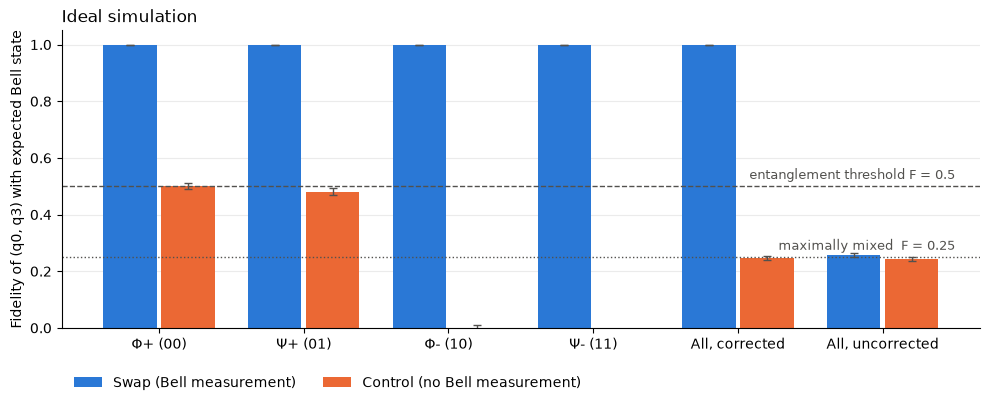

In [6]:
sim_result = StatevectorSampler(seed=1234).run(circuits, shots=SHOTS).result()
sim_swap_counts, sim_control_counts = split_results(sim_result)

sim_swap = analyze(sim_swap_counts)
sim_control = analyze(sim_control_counts)
print_summary("IDEAL SIMULATION — swap", sim_swap)
print()
print_summary("IDEAL SIMULATION — control (no BSM)", sim_control)
plot_fidelities(sim_swap, sim_control, "Ideal simulation");

## Part 2 — Run on IBM Quantum hardware

### 2a. Connect and pick a backend

In [7]:
token = os.getenv("QISKIT_IBM_TOKEN")
if not token:
    raise RuntimeError("QISKIT_IBM_TOKEN not found — create a .env file (see .env.example)")

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=token,
    instance=os.getenv("QISKIT_IBM_INSTANCE") or None,
)

if BACKEND_NAME:
    backend = service.backend(BACKEND_NAME)
else:
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=4)

status = backend.status()
print(f"Backend: {backend.name}  ({backend.num_qubits} qubits)  pending jobs: {status.pending_jobs}")

qiskit_runtime_service._discover_account:WARNING:2026-10-15 22:47:05,150: Loading account with the given token. A saved account will not be used.


Backend: ibm_marrakesh  (156 qubits)  pending jobs: 0


### 2b. Transpile to the backend's native gates (ISA circuits)

`optimization_level=3` lets the transpiler pick a good chain of 4 physical qubits for the swap circuit
(q0–q1–q2–q3 ideally sit on a line so no SWAPs are needed). That layout is then **fixed for every circuit**,
so the control (and Part 3) run on exactly the same physical qubits and the comparison is fair.

Physical qubits for (q0, q1, q2, q3): [149, 148, 147, 146]
swap_XX      physical qubits [149, 148, 147, 146]   depth  14   2q-depth 2
swap_YY      physical qubits [149, 148, 147, 146]   depth  14   2q-depth 2
swap_ZZ      physical qubits [149, 148, 147, 146]   depth  14   2q-depth 2
control_XX   physical qubits [149, 148, 147, 146]   depth  10   2q-depth 1
control_YY   physical qubits [149, 148, 147, 146]   depth   9   2q-depth 1
control_ZZ   physical qubits [149, 148, 147, 146]   depth   7   2q-depth 1


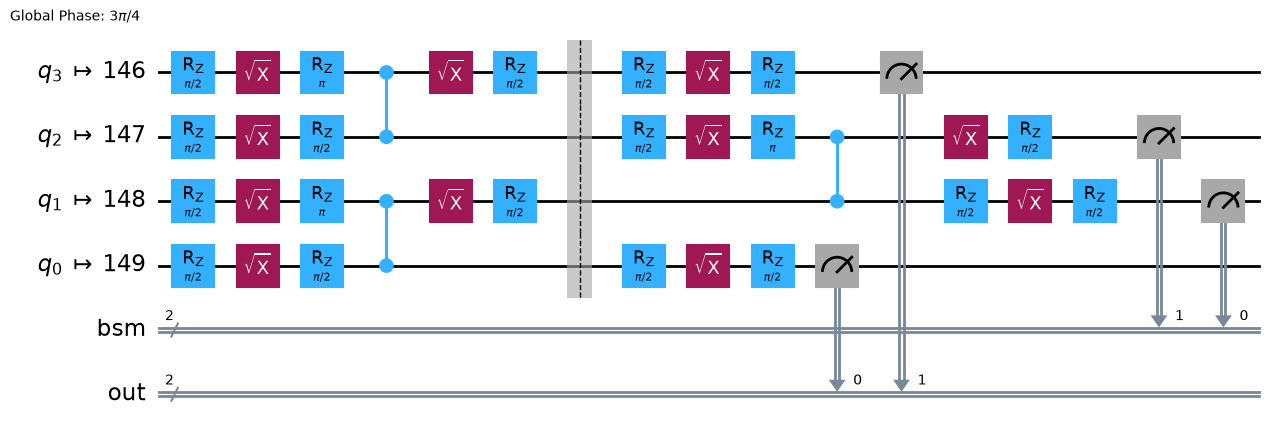

In [8]:
# 1) let the transpiler choose the best 4 qubits for the swap circuit
pm_search = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=1234)
LAYOUT = pm_search.run(swap_circuits[0]).layout.initial_index_layout(filter_ancillas=True)
print("Physical qubits for (q0, q1, q2, q3):", LAYOUT)

# 2) reuse that layout for every circuit
pm = generate_preset_pass_manager(backend=backend, optimization_level=3,
                                  initial_layout=LAYOUT, seed_transpiler=1234)
isa_circuits = pm.run(circuits)

for qc in isa_circuits:
    layout = qc.layout.final_index_layout()[:4]
    two_q = qc.depth(lambda inst: inst.operation.num_qubits == 2)
    print(f"{qc.name:<12} physical qubits {layout}   depth {qc.depth():>3}   2q-depth {two_q}")

isa_circuits[0].draw("mpl", idle_wires=False, fold=-1)

### 2c. Submit the job

All 6 circuits (3 swap + 3 control) go in **one** job. The job ID is saved to `results/`
so you can retrieve it later even if the kernel restarts.

In [9]:
sampler = Sampler(mode=backend)
job = sampler.run(isa_circuits, shots=SHOTS)
JOB_ID = job.job_id()

run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
(RESULTS_DIR / f"{run_stamp}_{backend.name}_job.txt").write_text(JOB_ID, encoding="utf-8")
print("Submitted job", JOB_ID, "on", backend.name)
print("Track it at https://quantum.cloud.ibm.com/workloads")

C:\Users\LOQ\AppData\Local\Temp\ipykernel_23088\2006797095.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Submitted job db8qokdckpjs73b1hp90 on ibm_marrakesh
Track it at https://quantum.cloud.ibm.com/workloads


### 2d. (Optional) Retrieve a previous job

If the queue was long and you came back later, paste the job ID here and run this cell
instead of 2c. You still need to run the cells in sections 0–2a.

In [10]:
# JOB_ID = "paste-job-id-here"
# job = service.job(JOB_ID)
# backend = job.backend()
# run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

### 2e. Results
`job.result()` blocks until the job finishes.

HARDWARE (ibm_marrakesh) — swap
  Φ+ (00)            F = 0.932 ± 0.006   entangled
  Ψ+ (01)            F = 0.929 ± 0.006   entangled
  Φ- (10)            F = 0.922 ± 0.006   entangled
  Ψ- (11)            F = 0.929 ± 0.006   entangled
  All, corrected     F = 0.928 ± 0.003   entangled
  All, uncorrected   F = 0.252 ± 0.007   -
  corrected <XX>, <YY>, <ZZ> = +0.907, -0.880, +0.924

HARDWARE (ibm_marrakesh) — control (no BSM)
  Φ+ (00)            F = 0.492 ± 0.011   -
  Ψ+ (01)            F = 0.500 ± 0.011   -
  Φ- (10)            F = 0.010 ± 0.012   -
  Ψ- (11)            F = -0.004 ± 0.012   -
  All, corrected     F = 0.260 ± 0.007   -
  All, uncorrected   F = 0.260 ± 0.007   -
  corrected <XX>, <YY>, <ZZ> = -0.009, -0.004, +0.043


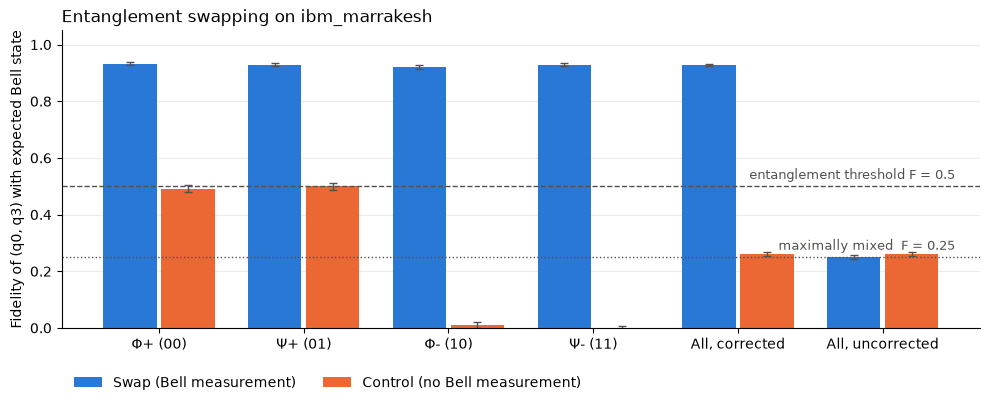

In [11]:
hw_result = job.result()
hw_swap_counts, hw_control_counts = split_results(hw_result)

hw_swap = analyze(hw_swap_counts)
hw_control = analyze(hw_control_counts)
print_summary(f"HARDWARE ({backend.name}) — swap", hw_swap)
print()
print_summary(f"HARDWARE ({backend.name}) — control (no BSM)", hw_control)

fig = plot_fidelities(hw_swap, hw_control, f"Entanglement swapping on {backend.name}")
fig.savefig(RESULTS_DIR / f"{run_stamp}_{backend.name}_fidelity.png", dpi=150)

In [12]:
record = {
    "experiment": "entanglement_swapping_postprocessed",
    "timestamp_utc": run_stamp,
    "backend": backend.name,
    "job_id": JOB_ID,
    "shots_per_circuit": SHOTS,
    "physical_qubits": LAYOUT,
    "qiskit": qiskit.__version__,
    "qiskit_ibm_runtime": qiskit_ibm_runtime.__version__,
    "swap": {"counts": hw_swap_counts, "summary": hw_swap},
    "control": {"counts": hw_control_counts, "summary": hw_control},
}
path = RESULTS_DIR / f"{run_stamp}_{backend.name}_results.json"
path.write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved", path)
print(f"\nLog line for CLAUDE.md:\n| {run_stamp} | {backend.name} | {JOB_ID} | post-processed | {SHOTS} "
      f"| {hw_swap['All, corrected']['F']:.3f} ± {hw_swap['All, corrected']['err']:.3f} "
      f"| {hw_control['All, corrected']['F']:.3f} | |")

Saved results\20261016T044714Z_ibm_marrakesh_results.json

Log line for CLAUDE.md:
| 20261016T044714Z | ibm_marrakesh | db8qokdckpjs73b1hp90 | post-processed | 4000 | 0.928 ± 0.003 | 0.260 | |


## Part 3 — *(optional)* Real-time feed-forward with a dynamic circuit

Here the Pauli correction is applied **on the quantum computer** during the circuit, using the
mid-circuit BSM result (`if_test`). If it works, every BSM outcome leaves (q0, q3) in $\Phi^+$ with no
software correction at all.

Expect a lower fidelity than Part 2: mid-circuit measurement + classical latency lets q0 and q3 decohere.
Set `RUN_DYNAMIC = True` in the config cell to run it.

In [13]:
if RUN_DYNAMIC:
    if "if_else" not in backend.target.operation_names:
        raise RuntimeError(f"{backend.name} does not support dynamic circuits (if_else)")

    ff_circuits = [build_swap_circuit(b, feed_forward=True) for b in BASES]
    ff_isa = pm.run(ff_circuits)
    ff_job = Sampler(mode=backend).run(ff_isa, shots=SHOTS)
    FF_JOB_ID = ff_job.job_id()
    ff_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    (RESULTS_DIR / f"{ff_stamp}_{backend.name}_ff_job.txt").write_text(FF_JOB_ID, encoding="utf-8")
    print("Submitted feed-forward job", FF_JOB_ID)
else:
    print("RUN_DYNAMIC is False — skipping Part 3")

RUN_DYNAMIC is False — skipping Part 3


In [14]:
if RUN_DYNAMIC:
    ff_result = ff_job.result()
    ff_counts = dict(zip(BASES, [joint_counts(r) for r in ff_result]))
    ff_summary = analyze(ff_counts, corrected_in_hardware=True)
    print_summary(f"HARDWARE ({backend.name}) — feed-forward (target Φ+ for every outcome)", ff_summary)

    fig = plot_fidelities(ff_summary, title=f"Feed-forward entanglement swapping on {backend.name}")
    fig.savefig(RESULTS_DIR / f"{ff_stamp}_{backend.name}_ff_fidelity.png", dpi=150)
    ff_record = {
        "experiment": "entanglement_swapping_feedforward",
        "timestamp_utc": ff_stamp, "backend": backend.name, "job_id": FF_JOB_ID,
        "shots_per_circuit": SHOTS, "counts": ff_counts, "summary": ff_summary,
    }
    (RESULTS_DIR / f"{ff_stamp}_{backend.name}_ff_results.json").write_text(
        json.dumps(ff_record, indent=2, ensure_ascii=False), encoding="utf-8")

## Interpreting the results

- **Swap, per-outcome F > 0.5** → q0 and q3 are entangled even though they never interacted. ✅
- **All, uncorrected ≈ 0.25** → without the BSM bits the pair looks completely random (no-signaling).
- **Control ≤ 0.5** per outcome (only classical ZZ correlation) and ≈ 0.25 corrected → the entanglement really comes
  from the Bell measurement, not from crosstalk.
- Hardware F is below 1 because of gate errors (4 CNOTs), readout errors and decoherence.

Record each run in the **Experiment log** in `CLAUDE.md` (the last cell of Part 2 prints a ready-made row).